# 07 · Bag of Words, TF-IDF y Word2Vec

**Etapas 4 y 5 del pipeline del Proyecto 2:** representaciones dispersas (BoW / TF-IDF) y estáticas densas (Word2Vec) del corpus de reseñas, siguiendo el laboratorio guía *Lab BoW - Word2Vec - BETO*.

**Corpus:** `data/processed/resenas_limpias.csv`: reseñas traducidas del Proyecto 1 (IMDb) y reseñas nativas en español (SensaCine).
**Código:** `src/embeddings_w2v.py`.

| Sección | Análisis del enunciado (5.1) | Rúbrica |
|---|---|---|
| 1 | Bag of Words y TF-IDF (representación dispersa) | Base para la comparación del notebook 09 |
| 2 | Entrenamiento de **CBOW** y **Skip-Gram** | Criterio 2 · 5 pts |
| 3 | **Campos semánticos** por género y polaridad (`most_similar`) | Criterio 2 · 5 pts |
| 4 | **Analogías vectoriales** (al menos 5) | Criterio 2 · 5 pts |
| 5 | **Similitud entre categorías**: género, polaridad y origen | Criterio 2 · 5 pts |
| 6 | **Vocabulario exclusivo** y calcos de traducción | Criterio 2 |
| 7 | Comparación con embeddings preentrenados (opcional) | Hallazgo adicional |
| 8 | Guardado de los embeddings (MongoDB y notebook 09) | — |

Las secciones de **Interpretación** se completan con los resultados obtenidos al ejecutar el notebook (criterio 2: interpretación contextualizada, 5 pts).

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Raíz del proyecto: el notebook se ejecuta desde la carpeta notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import embeddings_w2v as ew

# random_state = número de equipo (enunciado, sección 5.3)
NUMERO_EQUIPO = 1          # <- cambiar por el número de equipo
SEMILLA = NUMERO_EQUIPO
# workers=1 hace el entrenamiento reproducible; con más hilos es más rápido
# pero los vectores cambian un poco en cada ejecución.
WORKERS = 1

pd.set_option("display.max_colwidth", 200)
df = ew.cargar_corpus()
stopwords = ew.stopwords_es()
print(f"{len(df)} reseñas · {df['n_palabras_es'].sum():,} palabras")
pd.crosstab(df["genero_es"], [df["origen"], df["polaridad"]], margins=True, margins_name="Total")

16991 reseñas · 3,048,967 palabras


origen        nativo                    traducido                    Total
polaridad intermedia negativa positiva intermedia negativa positiva       
genero_es                                                                 
Acción            91       77      232        440      815     1745   3400
Animación         75       56      265        329      320     2349   3394
Comedia          103       73      223        362      741     1897   3399
Drama             52       82      266        295      608     2097   3400
Terror           121      103      174        428      873     1699   3398
Total            442      391     1160       1854     3357     9787  16991

## Preprocesamiento

- Cada reseña se divide en oraciones y palabras en minúscula (sin números ni puntuación). Word2Vec se entrena **con** las stopwords, porque son parte del contexto de cada palabra.
- Con `gensim.models.Phrases` se unen expresiones frecuentes de dos o más palabras en un solo token: `obra maestra` → `obra_maestra`, `banda sonora` → `banda_sonora`. Así se pueden consultar como una unidad (el enunciado pide explorar "obra maestra").
- Para los vectores de reseñas y categorías (secciones 5 y 6) se excluyen las stopwords


In [3]:
oraciones, tokens, oraciones_por_resena, frases = ew.preparar_oraciones(df["texto_es"])

print(f"Oraciones: {len(oraciones):,} · tokens: {sum(map(len, tokens)):,}")
expresiones = pd.Series([t for o in oraciones for t in o if "_" in t]).value_counts()
print(f"Expresiones unidas por Phrases: {len(expresiones):,}")
expresiones.head(20)

Oraciones: 183,105 · tokens: 2,805,109
Expresiones unidas por Phrases: 1,836


esta_película        18776
un_poco               3694
sin_embargo           3072
he_visto              2315
por_qué               2076
tal_vez               1648
para_mí               1438
al_final              1435
muy_bien              1297
un_buen               1269
no_puedo              1269
un_montón             1187
mucho_más             1163
por_supuesto          1031
me_gustó               983
al_menos               962
podría_haber           943
ni_siquiera            911
mejores_películas      865
vale_la_pena           864
Name: count, dtype: int64

---
## 1. Bag of Words y TF-IDF

**Bag of Words** representa cada reseña como el conteo de sus palabras; **TF-IDF** pondera ese conteo para penalizar las palabras que aparecen en casi todas las reseñas.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(max_features=20000, min_df=5, max_df=0.8,
                      stop_words=sorted(stopwords), token_pattern=r"(?u)\b[^\W\d_]{2,}\b")
X_bow = bow.fit_transform(df["texto_es"])

tfidf, X_tfidf = ew.construir_tfidf(df["texto_es"])
vocab_tfidf = tfidf.get_feature_names_out()

pd.DataFrame({
    "Bag of Words": [X_bow.shape[0], X_bow.shape[1], X_bow.nnz, f"{ew.dispersion(X_bow):.2f}%"],
    "TF-IDF": [X_tfidf.shape[0], X_tfidf.shape[1], X_tfidf.nnz, f"{ew.dispersion(X_tfidf):.2f}%"],
}, index=["reseñas", "dimensiones (vocabulario)", "valores distintos de cero", "dispersión"])

,Bag of Words,TF-IDF
reseñas,16991,16991
dimensiones (vocabulario),19777,19777
valores distintos de cero,963921,963921
dispersión,99.71%,99.71%


### 1.1 Términos más característicos de cada categoría (TF-IDF)

Para cada categoría se muestran los términos con mayor peso TF-IDF medio, **comparado con el resto de las reseñas** (diferencia de medias).

In [5]:
for columna in ["genero_es", "polaridad", "origen"]:
    terminos = ew.terminos_caracteristicos_tfidf(X_tfidf, vocab_tfidf, df[columna], n=12)
    print(f"\n=== {columna} ===")
    for categoria, lista in sorted(terminos.items()):
        print(f"  {categoria:<11} {', '.join(t for t, _ in lista)}")


=== genero_es ===
  Acción      acción, efectos, batman, bond, marvel, especiales, man, cómics, star, spiderman, superhéroes, men
  Animación   animación, disney, niños, pixar, voz, adultos, shrek, toy, animada, story, personajes, canciones
  Comedia     comedia, divertida, humor, divertido, sandler, comedias, divertidas, adam, gracioso, carrey, risas, hilarante
  Drama       libro, actuación, vida, guerra, amor, historia, oscar, actuaciones, drama, horas, cinematografía, hombre
  Terror      terror, horror, miedo, aterrador, scream, gore, original, asesino, aterradora, género, remake, sangre

=== polaridad ===
  intermedia  entretenida, interesante, esperaba, momentos, trama, mitad, premisa, problema, habría, predecible, original, decente
  negativa    horrible, dinero, mala, basura, terrible, minutos, siquiera, mierda, sentido, aburrida, aburrido, peores
  positiva    increíble, mejores, excelente, animación, genial, encantó, definitivamente, trabajo, vida, disney, encanta, impresio

### 1.2 Similitud entre categorías con TF-IDF

Similitud coseno entre los centroides TF-IDF de cada categoría. A la derecha, los centroides **centrados** (se resta el vector medio del corpus), que muestran solo lo que distingue a cada categoría.

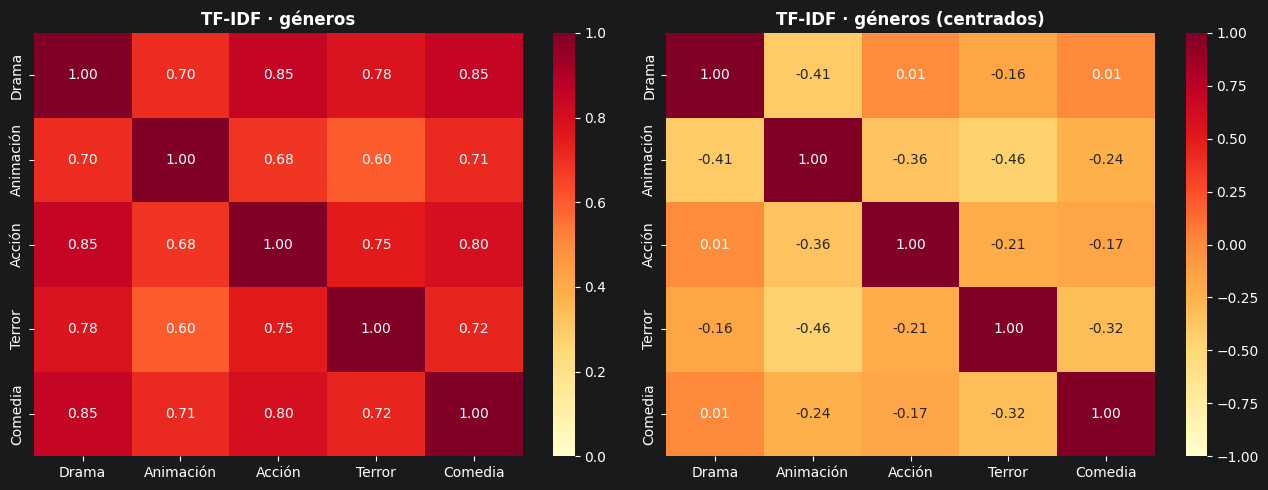

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, centrar in zip(axes, [False, True]):
    sns.heatmap(ew.similitud_centroides(X_tfidf, df["genero_es"], centrar=centrar),
                annot=True, fmt=".2f", cmap="YlOrRd", ax=ax, vmin=-1 if centrar else 0, vmax=1)
    ax.set_title("TF-IDF · géneros" + (" (centrados)" if centrar else ""), fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación (TF-IDF):** *completar con los resultados.* Guía:
- ¿Qué términos distinguen a cada género? ¿Son palabras temáticas (*miedo*, *animación*) o nombres de películas y actores?
- En el **origen**: ¿aparecen calcos del inglés en las reseñas traducidas (*realmente*, *definitivamente*, *actuación*, palabras en inglés sin traducir) y formas coloquiales en las nativas (*peli*, *pelicula* sin tilde)?
- Limitación de TF-IDF: solo compara **coincidencia de palabras**; *guion* y *argumento* son dimensiones distintas sin ninguna relación entre sí.

---
## 2. Entrenamiento de Word2Vec: CBOW y Skip-Gram

Se entrena Word2Vec **sobre el corpus propio** con gensim, en sus dos variantes:

| Parámetro | Valor | Motivo |
|---|---|---|
| `sg` | 0 = CBOW, 1 = Skip-Gram | Las dos variantes que pide el enunciado |
| `vector_size` | 150 | Dentro del rango habitual (100-300) para un corpus de ~3 millones de palabras |
| `window` | 5 | Contexto de 5 palabras a cada lado |
| `min_count` | 5 | Ignora palabras que aparecen menos de 5 veces (ruido, errores de tipeo) |
| `epochs` | 10 | Más pasadas que el valor por defecto (5), porque el corpus es pequeño |
| `seed` | número de equipo | Reproducibilidad |

**CBOW** predice la palabra central a partir de su contexto (más rápido, mejor con palabras frecuentes). **Skip-Gram** predice el contexto a partir de la palabra (más lento, mejor con palabras poco frecuentes).

In [7]:
modelos, tiempos = {}, {}
for nombre, sg in [("CBOW", 0), ("Skip-Gram", 1)]:
    modelos[nombre], tiempos[nombre] = ew.entrenar_word2vec(
        oraciones, sg=sg, vector_size=150, window=5, min_count=5, epochs=10,
        semilla=SEMILLA, workers=WORKERS)

ew.DIR_MODELOS.mkdir(parents=True, exist_ok=True)
for nombre, modelo in modelos.items():
    modelo.save(str(ew.DIR_MODELOS / f"word2vec_{nombre.lower().replace('-', '')}.model"))

pd.DataFrame({n: {"vocabulario": len(m.wv), "dimensiones": m.vector_size,
                  "segundos de entrenamiento": round(tiempos[n], 1)} for n, m in modelos.items()})

,CBOW,Skip-Gram
vocabulario,22696.0,22696.0
dimensiones,150.0,150.0
segundos de entrenamiento,41.8,121.4


### 2.1 El problema de BoW que resuelve Word2Vec

Como en la sección 1.4 del laboratorio: en Bag of Words cada palabra es una dimensión independiente (vector *one-hot*), así que la similitud entre dos palabras distintas siempre es **0**, sean sinónimos o no. Word2Vec sí captura que *guion* y *argumento* se usan en contextos parecidos.

In [8]:
pares = [("guion", "argumento"), ("guion", "trama"), ("actuación", "interpretación"),
         ("aburrida", "tediosa"), ("excelente", "magnífica"), ("terror", "miedo"),
         ("guion", "palomitas"), ("actuación", "terror")]

filas = []
for a, b in pares:
    fila = {"par": f"{a} - {b}", "BoW (one-hot)": 0.0}
    for nombre, modelo in modelos.items():
        fila[nombre] = round(float(modelo.wv.similarity(a, b)), 3) \
            if a in modelo.wv and b in modelo.wv else None
    filas.append(fila)
pd.DataFrame(filas).set_index("par")

,BoW (one-hot),CBOW,Skip-Gram
par,,,
guion - argumento,0.0,0.694,0.605
guion - trama,0.0,0.300,0.448
actuación - interpretación,0.0,0.691,0.577
aburrida - tediosa,0.0,0.740,0.727
excelente - magnífica,0.0,0.825,0.623
terror - miedo,0.0,0.473,0.522
guion - palomitas,0.0,0.269,0.275
actuación - terror,0.0,0.106,0.190


---
## 3. Campos semánticos

### 3.1 Vecinos semánticos de palabras clave

`most_similar()` sobre las palabras clave del enunciado y otras habituales en reseñas.

In [9]:
palabras_clave = ["guion", "actuación", "aburrida", "obra maestra", "predecible",
                  "final", "efectos especiales", "banda sonora", "ritmo", "emocionante",
                  "personajes", "fotografía"]
ew.tabla_vecinos(modelos, palabras_clave, n=8)

,CBOW,Skip-Gram
palabra,,
guion,"desarrollo_del_personaje, diseño_de_producción, guión, trabajo_de_cámara, estilo_visual, argumento, reparto, diálogo","guión, trabajo_de_cámara, estilo_visual, magnifico, depalma, aceptables, intacta, cuidada"
actuación,"interpretación, dirección, cinematografía, escritura, banda_sonora, ejecución, voz_actuando, partitura_musical","actuaciones, cinematografía, rendimiento, interpretación, voz_actuando, oldman, ejemplar, puntual"
aburrida,"lenta, tonta, estúpida, sangrienta, aterradora, tediosa, ridícula, confusa","tediosa, repetitiva, demasiado_larga, sosa, desarticulada, confusa, inventada, incoherente"
obra maestra,"joya, obra_de_arte, maravilla, verdadera_obra, pieza_maestra, pieza_de_arte, característica_animada, hazaña","obra_de_arte, pieza_maestra, joya, verdadera_obra, hazaña, epopeya, pieza_de_arte, debe_perderse"
predecible,"cursi, confusa, poco_realista, lenta, cojo, aburrida, confuso, aburrido","repetitiva, desarticulada, repetitivo, olvidable, previsible, trillado, incoherente, inconsistente"
final,"clímax, comienzo, cierre, al_final, principio, desenlace, título, giro","al_final, desenlace, clímax, twist, abrupto, anticlimático, cierre, giro"
efectos especiales,"efectos, efectos_visuales, gráficos, valores_de_producción, sets, trajes, escenarios, visuales","efectos_visuales, efectos, efectos_de_sonido, gráficos, deslumbrantes, sonoros, valores_de_producción, disfraces"
banda sonora,"cinematografía, fotografía, partitura, música, partitura_musical, voz_actuando, atmósfera, dirección","música, fotografía, partitura, partitura_musical, pista_de_sonido, voz_actuando, cinematografía, coreografía"
ritmo,"tono, diálogo, estado_de_ánimo, clímax, flujo, ambiente, comienzo, argumento","tempo, buen_ritmo, lento, quemador, flujo, tono, se_mueve, ritmo_rápido"


### 3.2 Clusters temáticos

Se definen los campos temáticos que menciona el enunciado y se mide la **similitud media dentro de cada campo y entre campos**. Si Word2Vec captura los campos semánticos, la diagonal debe ser mayor que el resto.

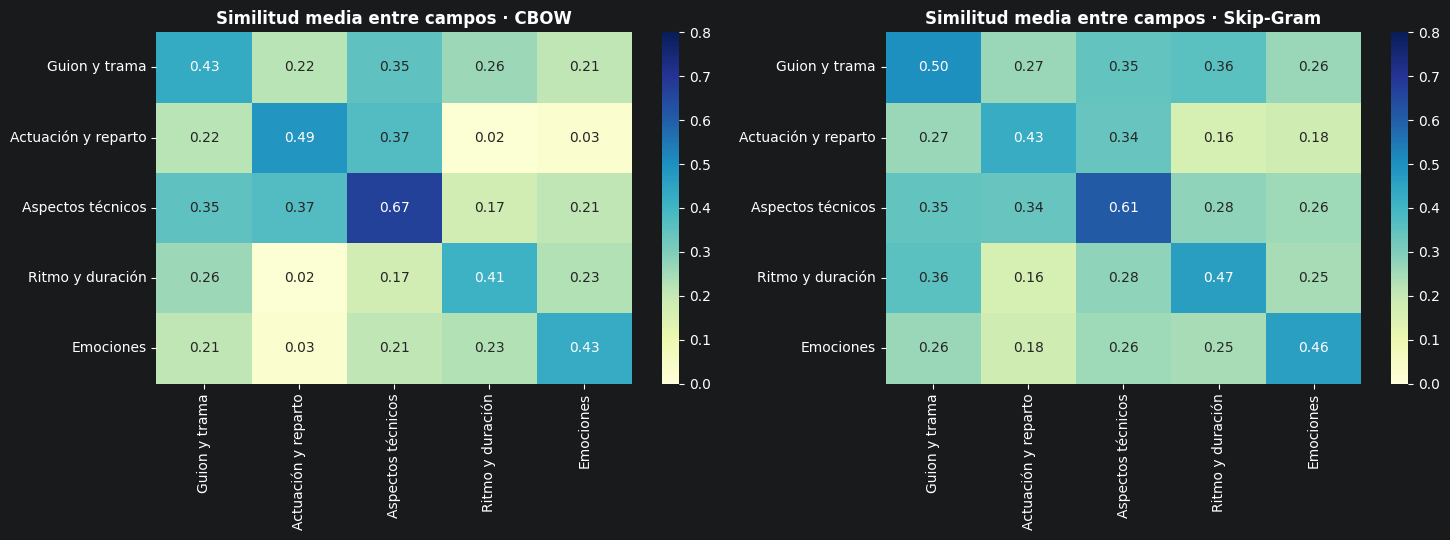

In [10]:
campos = {
    "Guion y trama":       ["guion", "trama", "argumento", "historia", "narrativa", "giros"],
    "Actuación y reparto": ["actuación", "interpretación", "reparto", "actor", "actriz", "elenco"],
    "Aspectos técnicos":   ["fotografía", "música", "efectos_especiales", "banda_sonora", "cinematografía", "sonido"],
    "Ritmo y duración":    ["ritmo", "lenta", "larga", "duración", "minutos", "lento"],
    "Emociones":           ["miedo", "risa", "lágrimas", "emoción", "tristeza", "nostalgia"],
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    sns.heatmap(ew.similitudes_grupos(modelo, campos).astype(float), annot=True, fmt=".2f",
                cmap="YlGnBu", ax=ax, vmin=0, vmax=0.8)
    ax.set_title(f"Similitud media entre campos · {nombre}", fontweight="bold")
plt.tight_layout()
plt.show()

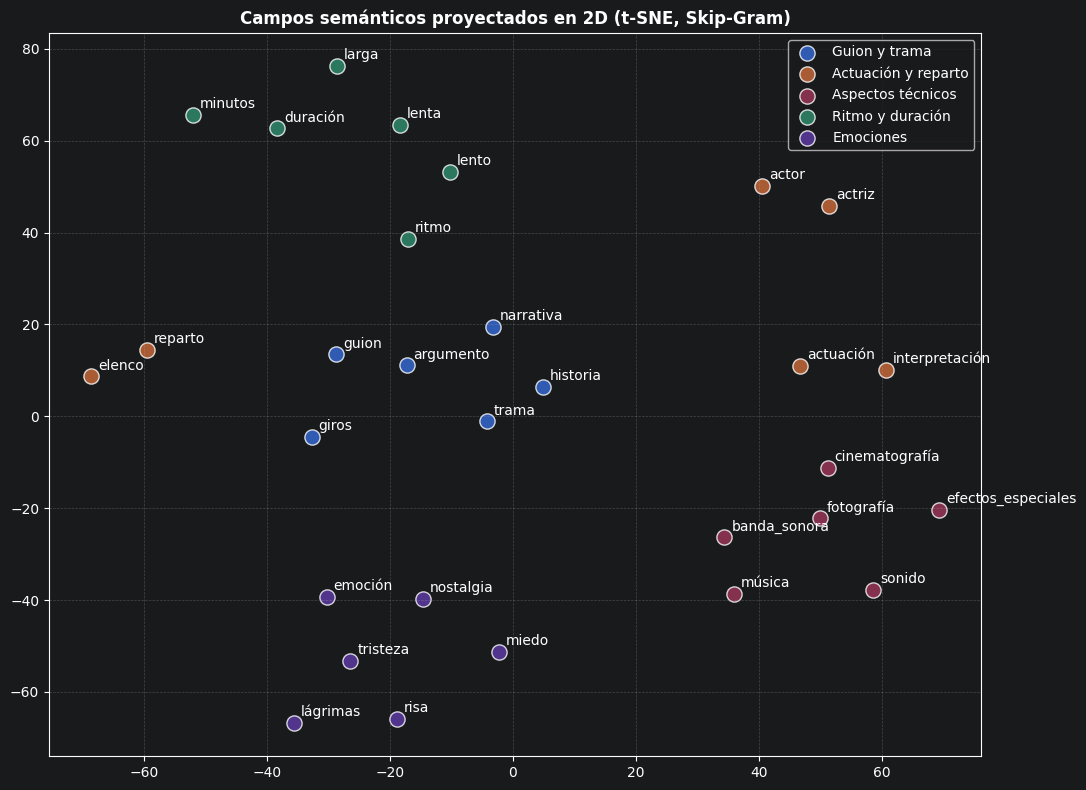

In [11]:
from sklearn.manifold import TSNE

modelo = modelos["Skip-Gram"]
palabras, categorias = [], []
for campo, lista in campos.items():
    for palabra in lista:
        if palabra in modelo.wv:
            palabras.append(palabra)
            categorias.append(campo)

coords = TSNE(n_components=2, random_state=SEMILLA, perplexity=8).fit_transform(
    np.array([modelo.wv[p] for p in palabras]))

fig, ax = plt.subplots(figsize=(11, 8))
for campo in campos:
    idx = [i for i, c in enumerate(categorias) if c == campo]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=120, label=campo, alpha=0.8, edgecolors="white")
    for i in idx:
        ax.annotate(palabras[i], coords[i], fontsize=10, xytext=(5, 5), textcoords="offset points")
ax.set_title("Campos semánticos proyectados en 2D (t-SNE, Skip-Gram)", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

### 3.3 Campos semánticos por polaridad y por género

Para ver cómo cambia el significado según el tipo de reseña, se entrena un modelo **CBOW por subconjunto** (reseñas positivas, negativas y cada género) y se comparan los vecinos de las mismas palabras. Los subconjuntos son más pequeños, así que algunos vecindarios serán más ruidosos (eso también es un hallazgo, según las preguntas frecuentes del enunciado).

In [12]:
def modelo_subconjunto(mascara):
    modelo, _ = ew.entrenar_word2vec(ew.oraciones_de(oraciones_por_resena, mascara), sg=0,
                                     vector_size=100, min_count=5, epochs=15,
                                     semilla=SEMILLA, workers=WORKERS)
    return modelo

modelos_polaridad = {p: modelo_subconjunto(df["polaridad"] == p) for p in ["positiva", "negativa"]}
ew.tabla_vecinos(modelos_polaridad, ["final", "guion", "actuación", "efectos_especiales",
                                     "personajes", "historia", "película"], n=6)

,positiva,negativa
palabra,,
final,"clímax, comienzo, al_final, resultado, cierre, desenlace","comienzo, trailer, giro, clímax, principio, tráiler"
guion,"guión, estilo_visual, humor_negro, diseño_de_producción, diálogo, ritmo","macho, entorno, alcance, conjunto, maquillaje, brillo"
actuación,"interpretación, escritura, dirección, rendimiento, ejecución, representación","ejecución, dirección, cinematografía, escritura, animación, música"
efectos_especiales,"efectos_visuales, efectos, gráficos, efectos_de_sonido, sets, trajes","efectos, gráficos, diálogos, chistes, trajes, sets"
personajes,"actores, personajes_principales, detalles, caracteres, aspectos, elementos","personajes_principales, efectos_especiales, actores, elementos, detalles, eventos"
historia,"trama, premisa, narrativa, historia_de_amor, narración, película","trama, premisa, idea, imagen, música, tensión"
película,"peli, pelicula, secuela, esta_película, cinta, cosa","secuela, cosa, pelicula, peli, idea, canción"


In [13]:
modelos_genero = {g: modelo_subconjunto(df["genero_es"] == g) for g in sorted(df["genero_es"].unique())}
ew.tabla_vecinos(modelos_genero, ["miedo", "final", "personajes", "efectos_especiales", "historia"], n=5).T

palabra,miedo,final,personajes,efectos_especiales,historia
Acción,"control, poder, trauma, conocimiento, derecho","comienzo, inicio, cierre, resto, tema","actores, aspectos, detalles, giros, momentos","efectos, efectos_visuales, increíbles, diálogos, visuales","trama, premisa, película, idea, violencia"
Animación,"dolor, aprender, espacio, felicidad, poder","comienzo, ritmo, tema, argumento, concepto","actores, detalles, momentos, gráficos, fondos","efectos, gráficos, efectos_visuales, talentos_de_voz, conjuntos","trama, premisa, sensación, narración, película"
Comedia,"precio, darse_cuenta, límite, vientre, fin","comienzo, concepto, título, mensaje, tráiler","actores, chistes, efectos_especiales, detalles, momentos","efectos, diálogos, trajes, números, chistes","trama, premisa, situación, idea, experiencia"
Drama,"poder, valor, significado, amor, fin","giro, libro, comienzo, clímax, título","diálogos, detalles, lugares, giros, efectos_especiales","diálogos, efectos_visuales, trajes, efectos, sets","trama, imagen, naturaleza, emoción, visión"
Terror,"sentido, terror, salto, potencial, ellas","clímax, concepto, giro, resultado, trailer","actores, personajes_principales, protagonistas, niños, giros","efectos, trajes, sets, giros, escenarios","trama, premisa, idea, imagen, emoción"


**Interpretación (campos semánticos):** *completar con los resultados.* Guía:
- ¿Qué tipo de vecinos da cada modelo? En general **CBOW** tiende a agrupar palabras que cumplen el mismo papel (*actuación* ↔ *dirección*, *cinematografía*) y **Skip-Gram** da vecinos más específicos y cercanos en significado (*aburrida* ↔ *tediosa*, *repetitiva*).
- ¿Se forman los cinco campos temáticos (diagonal alta en el heatmap, grupos separados en el t-SNE)? ¿Cuál campo es más difuso y por qué?
- Polaridad: ¿los vecinos de *final* o *guion* son positivos en el modelo de reseñas positivas (*sorprendente*, *brillante*) y negativos en el de negativas (*predecible*, *absurdo*)?
- Género: ¿*miedo* o *personajes* se asocian a palabras distintas en Terror que en Comedia o Animación?

---
## 4. Analogías vectoriales

Una analogía *a − b + c* busca la palabra cuyo vector está más cerca, la columna **esperada** indica la respuesta que se considera correcta; **¿acierta?** indica si aparece entre las 5 primeras.

In [14]:
analogias = [
    # (positivas, negativas, respuesta esperada)
    (["actor", "mujer"], ["hombre"], "actriz"),
    (["terror", "risa"], ["miedo"], "comedia"),
    (["película", "televisión"], ["cine"], "serie"),
    (["excelente", "mala"], ["buena"], "terrible"),
    (["director", "libro"], ["película"], "autor"),
    (["comedia", "miedo"], ["risa"], "terror"),
    (["actores", "actriz"], ["actor"], "actrices"),
]

filas = []
for positivas, negativas, esperada in analogias:
    for nombre, modelo in modelos.items():
        resultado, faltan = ew.analogia(modelo, positivas, negativas, n=5)
        palabras_resultado = [p for p, _ in resultado]
        filas.append({
            "analogía": f"{' + '.join(positivas)} − {' − '.join(negativas)}",
            "modelo": nombre,
            "esperada": esperada,
            "resultado (top 5)": ", ".join(f"{p} ({s})" for p, s in resultado) if resultado
                                 else f"fuera del vocabulario: {faltan}",
            "¿acierta?": "sí" if esperada in palabras_resultado else "no",
        })
tabla_analogias = pd.DataFrame(filas)
tabla_analogias

,analogía,modelo,esperada,resultado (top 5),¿acierta?
0,actor + mujer − hombre,CBOW,actriz,"actriz (0.786), elección (0.55), interpretación (0.541), opción (0.534), actuación (0.52)",sí
1,actor + mujer − hombre,Skip-Gram,actriz,"actriz (0.68), talentosa (0.543), reese_witherspoon (0.489), jennifer_lawrence (0.472), elena (0.456)",sí
2,terror + risa − miedo,CBOW,comedia,"comedia (0.668), comedia_romántica (0.61), historia_de_amor (0.574), acción (0.565), parodia (0.554)",sí
3,terror + risa − miedo,Skip-Gram,comedia,"comedia (0.53), bofetada (0.45), intocables (0.444), broma (0.444), chocolat (0.441)",sí
4,película + televisión − cine,CBOW,serie,"temporada (0.621), serie (0.613), serie_de_televisión (0.593), sección (0.58), segunda_mitad (0.561)",sí
5,película + televisión − cine,Skip-Gram,serie,"mm (0.487), vista_previa (0.482), serie_de_televisión (0.48), primera_mitad (0.478), terminada (0.469)",no
6,excelente + mala − buena,CBOW,terrible,"excepcional (0.753), sobresaliente (0.703), fenomenal (0.699), impecable (0.686), magnífica (0.654)",no
7,excelente + mala − buena,Skip-Gram,terrible,"magnífica (0.536), atroz (0.533), excepcional (0.521), mandarín (0.516), sobresaliente (0.51)",no
8,director + libro − película,CBOW,autor,"autor (0.725), sr (0.663), escritor (0.658), guionista (0.649), género_del_horror (0.635)",sí
9,director + libro − película,Skip-Gram,autor,"autor (0.558), guionista (0.533), escritor (0.52), productor (0.489), escritor_y_director (0.462)",sí


In [15]:
tabla_analogias.pivot(index="analogía", columns="modelo", values="¿acierta?")

modelo,CBOW,Skip-Gram
analogía,,
actor + mujer − hombre,sí,sí
actores + actriz − actor,no,sí
comedia + miedo − risa,sí,sí
director + libro − película,sí,sí
excelente + mala − buena,no,no
película + televisión − cine,sí,no
terror + risa − miedo,sí,sí


**Interpretación (analogías):** *completar con los resultados.* Guía:
- ¿Cuáles funcionan y en qué modelo? Las relaciones **gramaticales** (género masculino/femenino, singular/plural) suelen funcionar mejor que las **conceptuales** (*excelente − buena + mala*), porque aparecen de forma muy regular en el texto.
- Cuando falla, ¿la respuesta es razonable? Por ejemplo, *excelente − buena + mala* puede devolver sinónimos de *excelente* (el modelo no separa bien la escala de calidad, porque *buena* y *mala* aparecen en contextos casi idénticos: "la película es ___").
- *película − cine + televisión*: ¿aparece *serie*? El corpus casi no tiene reseñas de series, así que esa relación está poco representada.
- Efecto del tamaño del corpus: ~3 millones de palabras es poco para Word2Vec; analogías que funcionan con modelos entrenados en miles de millones de palabras pueden fallar aquí.

---
## 5. Similitud entre categorías

Cada reseña se representa con el **promedio de los vectores de sus palabras** (sin stopwords). Con esos vectores se calcula el **centroide** de cada género, polaridad y origen, y la similitud coseno entre centroides.

Se usa el modelo **Skip-Gram** para los vectores de reseñas (cambiar `MODELO_RESENAS` para usar CBOW).

Matriz de embeddings de reseñas: (16991, 150)


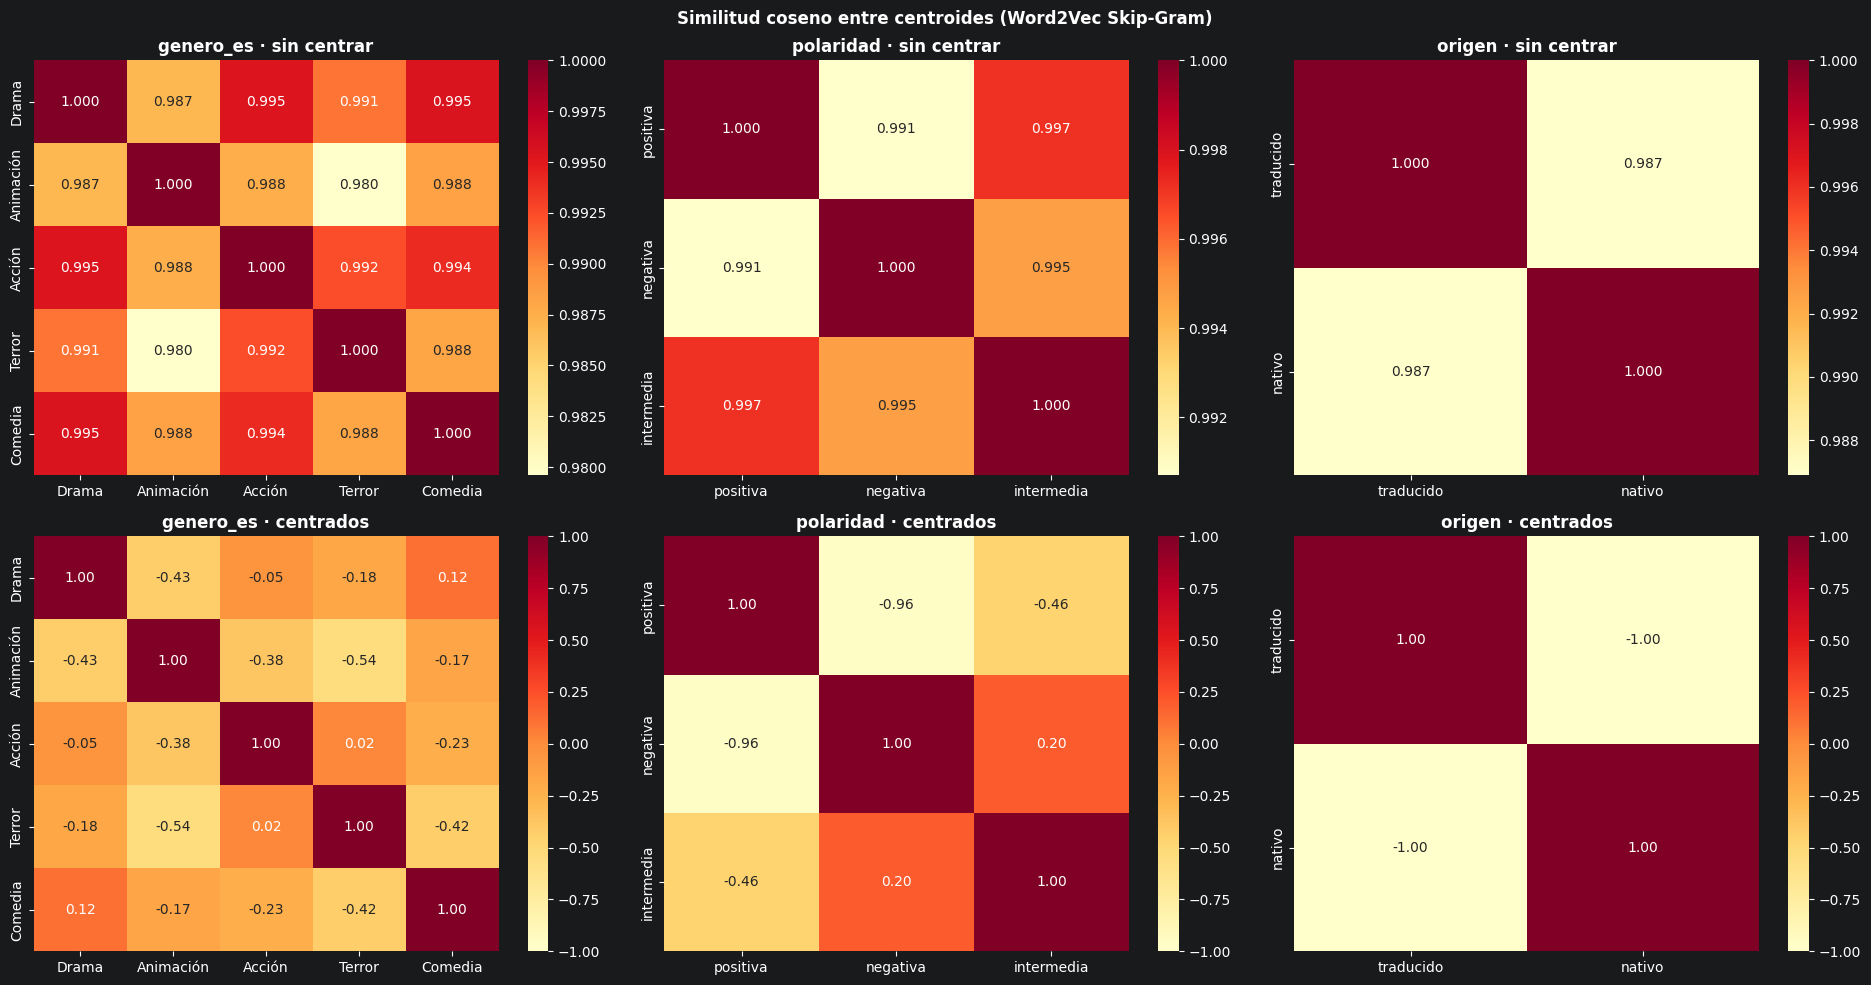

In [16]:
MODELO_RESENAS = "Skip-Gram"
X_w2v = ew.matriz_resenas(tokens, modelos[MODELO_RESENAS], stopwords)
print(f"Matriz de embeddings de reseñas: {X_w2v.shape}")

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for col, columna in enumerate(["genero_es", "polaridad", "origen"]):
    for fila, centrar in enumerate([False, True]):
        ax = axes[fila, col]
        sns.heatmap(ew.similitud_centroides(X_w2v, df[columna], centrar=centrar), annot=True,
                    fmt=".3f" if not centrar else ".2f", cmap="YlOrRd", ax=ax,
                    vmin=None if not centrar else -1, vmax=1)
        ax.set_title(f"{columna} · {'centrados' if centrar else 'sin centrar'}", fontweight="bold")
plt.suptitle(f"Similitud coseno entre centroides (Word2Vec {MODELO_RESENAS})", fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
sim_generos = ew.similitud_centroides(X_w2v, df["genero_es"], centrar=True)
pares_generos = (sim_generos.where(np.triu(np.ones(sim_generos.shape, dtype=bool), k=1))
                 .stack().dropna().sort_values(ascending=False))
print("Géneros más cercanos (centroides centrados):")
print(pares_generos.round(3).to_string())

Géneros más cercanos (centroides centrados):
Drama      Comedia      0.115
Acción     Terror       0.022
Drama      Acción      -0.047
Animación  Comedia     -0.171
Drama      Terror      -0.179
Acción     Comedia     -0.226
Animación  Acción      -0.376
Terror     Comedia     -0.424
Drama      Animación   -0.427
Animación  Terror      -0.539


### 5.1 ¿Se parecen más las reseñas traducidas entre sí que a las nativas?

Similitud coseno media entre pares de reseñas (muestra de 1 500 de cada grupo).

In [18]:
origenes = [("traducido", "traducido"), ("nativo", "nativo"), ("traducido", "nativo")]
pd.DataFrame([{"grupo A": a, "grupo B": b,
               "Word2Vec": round(ew.similitud_media_entre(X_w2v, df["origen"], a, b, semilla=SEMILLA), 4),
               "TF-IDF": round(ew.similitud_media_entre(X_tfidf, df["origen"], a, b, semilla=SEMILLA), 4)}
              for a, b in origenes])

,grupo A,grupo B,Word2Vec,TF-IDF
0,traducido,traducido,0.8655,0.0154
1,nativo,nativo,0.7935,0.0122
2,traducido,nativo,0.8181,0.0090


**Interpretación (similitud entre categorías):** *completar con los resultados.* Guía:
- Sin centrar, todas las similitudes son muy altas (~0,98-0,99): todas las reseñas hablan de cine y comparten la mayor parte del vocabulario. Por eso conviene mirar los centroides **centrados**.
- ¿Qué géneros son semánticamente más cercanos? (Por ejemplo, ¿Acción con Drama o con Terror? ¿Animación es el más aislado?)
- Polaridad: ¿la reseña intermedia queda entre la positiva y la negativa?
- Origen: si la similitud *traducido-traducido* es mayor que *traducido-nativo*, las traducciones automáticas comparten un estilo propio (vocabulario del traductor) que las distingue del español nativo. Tener en cuenta también que las nativas vienen de otra fuente (SensaCine) y de otras películas.

---
## 6. Vocabulario exclusivo

Palabras características de cada categoría **según su posición en el espacio vectorial**: las más cercanas a la dirección *(centroide de la categoría − centroide del resto)*, filtradas para que sean al menos 1,5 veces más frecuentes (en proporción) dentro de la categoría que fuera de ella.

In [19]:
modelo = modelos[MODELO_RESENAS]
for columna in ["genero_es", "polaridad", "origen"]:
    vocabulario = ew.vocabulario_caracteristico(modelo, X_w2v, df[columna], tokens, stopwords, n=12)
    print(f"\n=== {columna} ===")
    for categoria, tabla in sorted(vocabulario.items()):
        print(f"  {categoria:<11} {', '.join(tabla['palabra']) if len(tabla) else '(sin palabras)'}")


=== genero_es ===
  Acción      iron_man, x-men, estelar, x, spidey, spiderman, james_bond, bourne, war, blade, doom, explosiones
  Animación   ratatouille, aladdin, disney, animación, pixar, encontrar_a_nemo, encontrando_a_nemo, monsters_inc, toy_story, tangled, ghibli, despreciable_me
  Comedia     amanda, maggie, perry, kathy, jennifer_aniston, christine, zellweger, paul_rudd, renee, farrell, seyfried, collette
  Drama       turing, fletcher, nash, brandon, juicio, codicia, ambición, jurado, sacrificio, rita, maya, fassbender
  Terror      horror, terror, gore, salto, actividad_paranormal, daba_miedo, slasher, asustarte, tortura, scream, miedos_de_salto, saw

=== polaridad ===
  intermedia  hacia_el_final, resolución, confusa, narrativa, predecible, previsible, obvia, lenta, graciosos, floja, segunda_mitad, se_volvió
  negativa    apagarlo, inútil, gasté, este_pedazo, siquiera, qué_demonios, vomitar, irme, advertir, basura, tonterías, gastar
  positiva    danny_elfman, docter, will

### 6.1 Calcos de traducción

Frecuencia relativa (por cada 10 000 palabras) de expresiones que suelen aparecer en traducciones automáticas del inglés, comparada con su uso en las reseñas nativas.

In [20]:
frec = ew.frecuencias_por_categoria(tokens, df["origen"], stopwords=set())
totales = {o: sum(c.values()) for o, c in frec.items()}

candidatas = ["realmente", "definitivamente", "actuación", "actuaciones", "actuar", "básicamente",
              "totalmente", "honestamente", "the", "film", "peli", "pelicula", "película", "filme",
              "guion", "guión", "argumento", "trama"]
calcos = pd.DataFrame({o: [frec[o][p] / totales[o] * 10000 for p in candidatas] for o in frec},
                      index=candidatas).round(2)
calcos["traducido / nativo"] = (calcos["traducido"] / calcos["nativo"].replace(0, np.nan)).round(1)
calcos.sort_values("traducido / nativo", ascending=False)

,traducido,nativo,traducido / nativo
definitivamente,4.67,0.40,11.7
básicamente,1.72,0.28,6.1
actuar,1.26,0.23,5.5
honestamente,1.37,0.28,4.9
realmente,25.09,5.36,4.7
actuación,13.76,3.84,3.6
the,9.97,4.06,2.5
película,130.89,96.30,1.4
trama,11.81,12.14,1.0
totalmente,2.68,2.94,0.9


**Interpretación (vocabulario exclusivo):** *completar con los resultados.* Guía:
- Géneros: ¿el vocabulario es temático (Terror: *gore*, *slasher*, *sustos*) o son nombres de películas, personajes y actores? Esto muestra que Word2Vec también aprende **entidades** del dominio.
- Polaridad: ¿qué adjetivos son exclusivos de las negativas?
- Origen: ¿aparecen calcos en las traducidas (*realmente* por *really*, *definitivamente* por *definitely*, *actuación* por *acting*) y registro coloquial en las nativas (*peli*, *pelicula* sin tilde, *film*)?

**Interpretación:** *completar.* ¿El modelo genérico asocia *final* o *efectos* con su sentido general (*final* de un partido, *efectos* secundarios) mientras que el propio los asocia con el cine?

---
## 8. Guardado

- `data/results/embeddings_word2vec.npz`: vector de cada reseña (`ids`, `vectores`). Lo carga la migración a MongoDB (`embeddings.word2vec_avg`) y el notebook 09.
- `data/results/tfidf.npz` y `tfidf_meta.npz`: matriz TF-IDF para el notebook 09.
- `data/models/`: los dos modelos Word2Vec (se guardaron en la sección 2).

In [21]:
ew.guardar_embeddings(df["id"], X_w2v)
ew.guardar_tfidf(df["id"], X_tfidf, vocab_tfidf)
print("Guardado:", ew.RUTA_EMBEDDINGS_W2V.relative_to(RAIZ), X_w2v.shape)
print("Guardado:", ew.RUTA_TFIDF.relative_to(RAIZ), X_tfidf.shape)

Guardado: data\results\embeddings_word2vec.npz (16991, 150)
Guardado: data\results\tfidf.npz (16991, 19777)
